# Exploratory Data Analysis
**ResolveX — M2: Data Preparation & EDA**

This notebook analyzes the prepared datasets to understand class distribution, text characteristics, temporal coverage, and answer availability.

**Reads from `data/processed/`:** `ml_dataset.csv`, `knowledge_base.jsonl`, `retrieval_eval.csv`.

## 1. Setup

Import dependencies and configure paths.

In [1]:
from pathlib import Path
import sys
import csv
import json
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

cwd = Path.cwd().resolve()
ROOT = next((folder for folder in (cwd, *cwd.parents)
             if (folder / "src" / "data" / "preprocessing.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open the notebook within the ResolveX repository")
sys.path.insert(0, str(ROOT))

ML_OUT   = ROOT / "data" / "processed" / "ml_dataset.csv"
KB_OUT   = ROOT / "data" / "processed" / "knowledge_base.jsonl"
EVAL_OUT = ROOT / "data" / "processed" / "retrieval_eval.csv"

for path in (ML_OUT, KB_OUT, EVAL_OUT):
    if not path.exists():
        raise FileNotFoundError(f"Run 03_data_preparation.ipynb first: {path}")

## 2. Class Distribution

Count questions per category in the ML dataset and measure class imbalance.

In [2]:
label_counts = Counter()
with ML_OUT.open(encoding="utf-8", newline="") as f:
    for row in csv.DictReader(f):
        label_counts[row["Label"]] += 1

total = sum(label_counts.values())
print(f"Total single-category questions: {total:,}\n")
print(f"{'Category':<30} {'Count':>8}  {'Share':>7}")
print("-" * 50)
for label, n in sorted(label_counts.items(), key=lambda x: -x[1]):
    print(f"{label:<30} {n:>8,}  {n/total:>6.1%}")

Total single-category questions: 177,194

Category                          Count    Share
--------------------------------------------------
Hardware & Drivers               43,777   24.7%
Software & Packages              43,585   24.6%
Network & Connectivity           30,107   17.0%
Boot & Startup                   27,048   15.3%
Storage & Filesystems            17,841   10.1%
Access & Permissions             14,836    8.4%


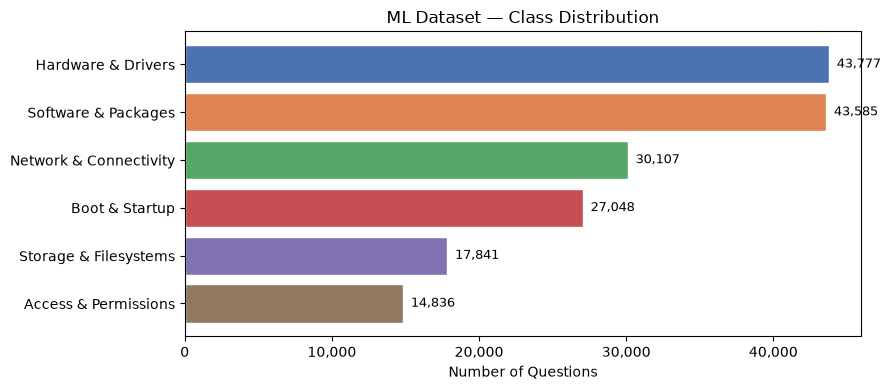

In [3]:
labels  = [l for l, _ in sorted(label_counts.items(), key=lambda x: -x[1])]
counts  = [label_counts[l] for l in labels]
colors  = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860"]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(labels[::-1], counts[::-1], color=colors[::-1], edgecolor="white")
ax.set_xlabel("Number of Questions")
ax.set_title("ML Dataset — Class Distribution")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
for bar, n in zip(bars, counts[::-1]):
    ax.text(bar.get_width() + total * 0.003, bar.get_y() + bar.get_height() / 2,
            f"{n:,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## 3. Text Characteristics

Measure title length, body length (in characters), and word count across the ML dataset.

In [4]:
title_lens = []
body_lens  = []
body_words = []

with ML_OUT.open(encoding="utf-8", newline="") as f:
    for row in csv.DictReader(f):
        title = row.get("Title", "")
        body  = row.get("BodyText", "")
        title_lens.append(len(title))
        body_lens.append(len(body))
        body_words.append(len(body.split()))

df_text = pd.DataFrame({"title_chars": title_lens,
                         "body_chars":  body_lens,
                         "body_words":  body_words})
print(df_text.describe().round(1))

       title_chars  body_chars  body_words
count     177194.0    177194.0    177194.0
mean          52.7      1345.6       178.6
std           21.1      2402.8       256.6
min           13.0        27.0         4.0
25%           38.0       386.0        64.0
50%           49.0       679.0       108.0
75%           64.0      1304.0       192.0
max          150.0     31410.0      5075.0


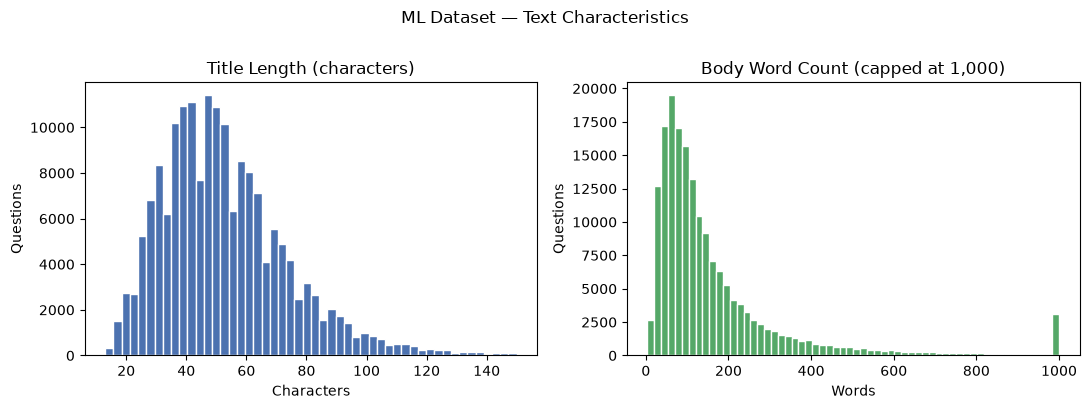

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df_text["title_chars"], bins=50, color="#4C72B0", edgecolor="white")
axes[0].set_title("Title Length (characters)")
axes[0].set_xlabel("Characters")
axes[0].set_ylabel("Questions")

axes[1].hist(df_text["body_words"].clip(upper=1000), bins=60, color="#55A868", edgecolor="white")
axes[1].set_title("Body Word Count (capped at 1,000)")
axes[1].set_xlabel("Words")
axes[1].set_ylabel("Questions")

plt.suptitle("ML Dataset — Text Characteristics", y=1.01)
plt.tight_layout()
plt.show()

## 4. Temporal Coverage

Analyze how the ML dataset questions are distributed over time.

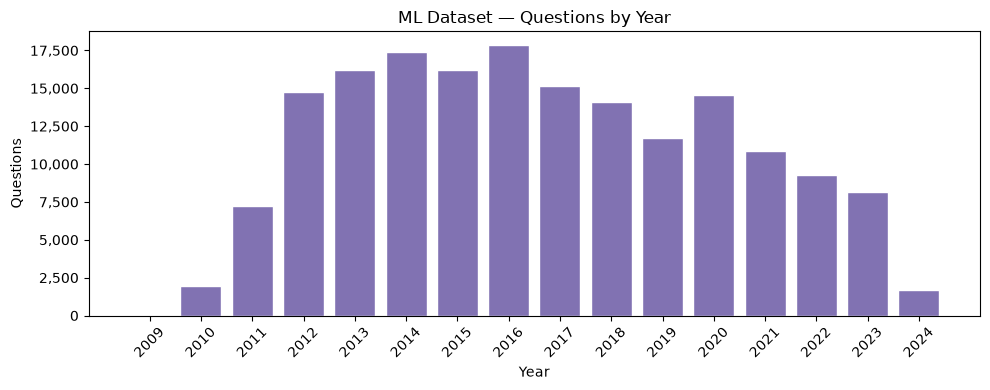

Years covered: 2009 – 2024


In [6]:
year_counts = Counter()
with ML_OUT.open(encoding="utf-8", newline="") as f:
    for row in csv.DictReader(f):
        date = row.get("CreationDate", "")
        if len(date) >= 4:
            year_counts[date[:4]] += 1

years  = sorted(year_counts)
counts = [year_counts[y] for y in years]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(years, counts, color="#8172B2", edgecolor="white")
ax.set_title("ML Dataset — Questions by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Questions")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"Years covered: {years[0]} – {years[-1]}")

## 5. Answer-Related Characteristics

Analyze accepted-answer availability and answer count distribution across the knowledge base.

In [7]:
answer_counts    = []
has_accepted     = 0
kb_total         = 0

with KB_OUT.open(encoding="utf-8") as f:
    for line in f:
        record = json.loads(line)
        kb_total += 1
        answer_counts.append(len(record["answers"]))
        has_accepted += record["accepted_answer_id"] is not None

print(f"Knowledge base questions  : {kb_total:,}")
print(f"With valid accepted answer : {has_accepted:,}  ({has_accepted/kb_total:.1%})")
print(f"\nAnswer count per question:")
s = pd.Series(answer_counts)
print(s.describe().round(1))

Knowledge base questions  : 318,537
With valid accepted answer : 136,151  (42.7%)

Answer count per question:
count    318537.0
mean          1.6
std           1.4
min           1.0
25%           1.0
50%           1.0
75%           2.0
max          82.0
dtype: float64


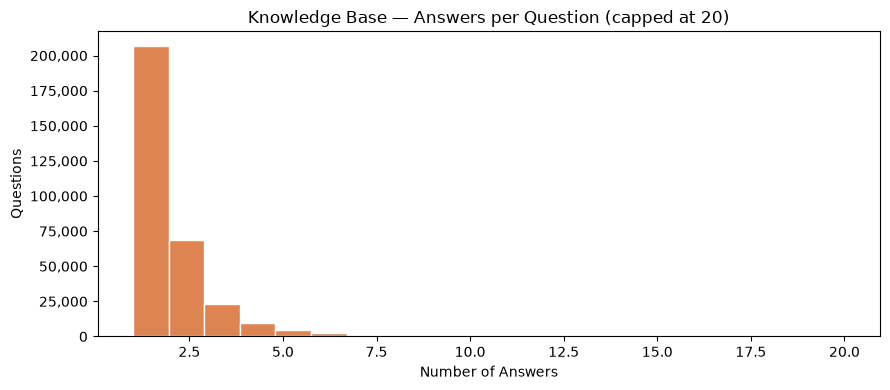

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(pd.Series(answer_counts).clip(upper=20), bins=20, color="#DD8452", edgecolor="white")
ax.set_title("Knowledge Base — Answers per Question (capped at 20)")
ax.set_xlabel("Number of Answers")
ax.set_ylabel("Questions")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

## 6. Retrieval Evaluation Data

Examine the duplicate-pair distribution: how many unique source questions have at least one duplicate.

In [9]:
from collections import defaultdict

duplicates_per_question = defaultdict(int)
with EVAL_OUT.open(encoding="utf-8", newline="") as f:
    for row in csv.DictReader(f):
        duplicates_per_question[row["QuestionId"]] += 1

total_pairs     = sum(duplicates_per_question.values())
unique_questions = len(duplicates_per_question)
print(f"Total duplicate pairs         : {total_pairs:,}")
print(f"Unique source questions        : {unique_questions:,}")
print(f"Avg duplicates per question    : {total_pairs / unique_questions:.2f}")

dup_dist = Counter(duplicates_per_question.values())
print("\nDistribution of duplicate count per question (top 10):")
for n, freq in sorted(dup_dist.items())[:10]:
    print(f"  {n} duplicate(s) : {freq:,} questions")

Total duplicate pairs         : 41,411
Unique source questions        : 37,132
Avg duplicates per question    : 1.12

Distribution of duplicate count per question (top 10):
  1 duplicate(s) : 33,214 questions
  2 duplicate(s) : 3,593 questions
  3 duplicate(s) : 293 questions
  4 duplicate(s) : 28 questions
  5 duplicate(s) : 4 questions


## Findings

### Class Distribution

- Six categories are represented in the ML dataset; distribution is documented above.
- The largest class is approximately three times the smallest. Report macro F1 and per-class metrics; compare class weighting on validation data rather than balancing blindly.

### Text Characteristics

- Title and body length distributions are documented above.
- Code, links and image descriptions are preserved. Body lengths have a long tail: evaluate truncation effects before imposing input limits. Image descriptions are not OCR.

### Temporal Coverage

- Questions cover 2009-2024. Historical coverage does not guarantee that troubleshooting applies to current Ubuntu versions; 2024 is a partial dump year.

### Answer Coverage

- Every knowledge base question has at least one linked answer by construction; this does not establish that the issue is solved.
- Accepted-answer availability is documented above.
- Invalid accepted-answer references were excluded during data preparation.

### Retrieval Evaluation Data

- Duplicate pairs provide a relevance signal for retrieval evaluation.
- These pairs will be used to measure Recall@K and MRR in M4.